In [ ]:
import os
for f in os.listdir("/content"):
  if f.endswith(".zip"):
    print(f)

ace_equilibrium_spectra_output.zip
disequil_spectra_output_8k.zip
freckll_survey_output.zip
clean_final_spec.npy.zip


In [ ]:
!unzip -q /content/ace_equilibrium_spectra_output.zip -d /content/ace_equilibrium_spectra_output
!unzip -q /content/disequil_spectra_output_8k.zip -d /content/disequil_spectra_output_8k
!unzip -q /content/clean_final_spec.npy.zip -d /content/clean_final_spec.npy

In [ ]:
import glob
import numpy as np
ace = glob.glob("/content/ace_equilibrium_spectra_output/**/spec_*.npy",recursive=True)
print("ACE: ",len(ace))
disequi = glob.glob("/content/disequil_spectra_output_8k/**/spec_*.npy",recursive=True)
print("Disequi: ",len(disequi))
free_tot = "/content/clean_final_spec.npy/clean_final_spec.npy"
free_spectra = np.load(free_tot)
print("Free: ",len(free_spectra))

ACE:  8426
Disequi:  8426
Free:  98495


In [ ]:
print(ace[0])
print(disequi[0])
print(free_spectra[0])

/content/ace_equilibrium_spectra_output/ace_equilibrium_spectra_output/spec_06556.npy
/content/disequil_spectra_output_8k/disequil_spectra_output_8k/spec_06556.npy
[ 1.37254686e-02  1.36939745e-02  1.36925365e-02  1.37164956e-02
  1.37000321e-02  1.37963331e-02  1.37310109e-02  1.37244899e-02
  1.37924931e-02  1.38169302e-02  1.38161149e-02  1.38039475e-02
  1.37839721e-02  1.37624181e-02  1.37555966e-02  1.37588477e-02
  1.37663848e-02  1.37681209e-02  1.37740164e-02  1.37735074e-02
  1.37779587e-02  1.38009039e-02  1.38257078e-02  1.38261597e-02
  1.38666930e-02  1.39330383e-02  1.39069914e-02  1.39170726e-02
  1.38801184e-02  1.38390843e-02  1.38142801e-02  1.37990011e-02
  1.37824372e-02  1.37810202e-02  1.37712863e-02  1.37777800e-02
  1.37604827e-02  1.37541036e-02  1.37335991e-02  1.37143588e-02
  1.37004396e-02  1.36977601e-02  1.37188464e-02  1.39859062e-02
  1.38622851e-02  1.37959771e-02  1.38035542e-02  1.38195252e-02
  1.38231240e-02  1.38259125e-02  1.38378125e-02  1.3821

In [ ]:
ace_spectra = np.array([np.load(p) for p in sorted(ace)])
print(ace_spectra.shape)
disequi_spectra = np.array([np.load(d) for d in sorted(disequi)])
print(disequi_spectra.shape)
print(free_spectra.shape)
print(ace_spectra[0])
print(disequi_spectra[0])
print(free_spectra[0])

(8426, 52)
(8426, 52)
(98495, 62)
[0.02313491 0.02311165 0.02325903 0.02337712 0.02339113 0.02356175
 0.02353939 0.02349246 0.02358825 0.02358229 0.02359797 0.02358795
 0.02358023 0.02355358 0.02353335 0.02349941 0.02349287 0.02351231
 0.02353109 0.02357084 0.02361164 0.02364457 0.02365619 0.02365524
 0.02364046 0.0236535  0.02367442 0.02368051 0.02367376 0.02368692
 0.02368061 0.02367781 0.02367167 0.02366028 0.0236499  0.02363757
 0.02361627 0.02360577 0.02359023 0.0235744  0.02355541 0.02353057
 0.02353133 0.02358875 0.02363113 0.02363789 0.02365711 0.02365542
 0.023639   0.0236443  0.02370113 0.02369012]
[0.02313491 0.02311169 0.02325944 0.02337827 0.02339233 0.02356649
 0.02354311 0.02349537 0.02359426 0.02358801 0.02360421 0.02359376
 0.02358547 0.02355771 0.02353682 0.02350206 0.02349548 0.02351497
 0.02353448 0.02357547 0.02361835 0.02365315 0.023666   0.02366455
 0.02364896 0.02366342 0.02368565 0.02369187 0.02368453 0.02369863
 0.02369184 0.02368888 0.02368214 0.02366984 0.02

In [ ]:
free_T = free_spectra[:, 55]
free_spectra = free_spectra[:, :52]
print(free_spectra.shape)
print(free_T[:5])

(98495, 52)
[ 724.04573717  557.87366806  672.43583878 1578.42137017 2688.24186075]


In [ ]:
!unzip -q /content/freckll_survey_output.zip -d /content/freckll_survey_output

In [ ]:
found = glob.glob("/content/freckll_survey_output/**/params.json", recursive=True)
print("params.json files found:", len(found))
if found:
    print("example:", found[0])

params.json files found: 8426
example: /content/freckll_survey_output/freckll_survey_output/planet_3571/params.json


In [ ]:
planet_dirs = glob.glob("/content/freckll_survey_output/freckll_survey_output/planet_*")
# show a few folder names
for p in sorted(planet_dirs)[:5]:
    print(os.path.basename(p))

planet_0000
planet_0001
planet_0002
planet_0003
planet_0005


In [ ]:
# the SAME sorted folder list the notebook used
planet_dirs_sorted = sorted(glob.glob("/content/freckll_survey_output/freckll_survey_output/planet_*"))
print("Number of folders:", len(planet_dirs_sorted))

# temperature by POSITION (index i), matching spec_{i}.npy
import json
temps_by_position = []
for pdir in planet_dirs_sorted:
    with open(f"{pdir}/params.json") as f:
        temps_by_position.append(json.load(f)["Teq_K"])
temps_by_position = np.array(temps_by_position)
print("temps_by_position shape:", temps_by_position.shape)

Number of folders: 8426
temps_by_position shape: (8426,)


In [ ]:
import os

ace_sorted = sorted(ace)   # same order as ace_spectra was built

ace_T = []
for path in ace_sorted:
    # the number in the filename IS the position index
    pos = int(os.path.basename(path).split("_")[1].split(".")[0])
    ace_T.append(temps_by_position[pos])

ace_T = np.array(ace_T)
print("ace_T shape:", ace_T.shape)
print("first 5 temps:", ace_T[:5])

ace_T shape: (8426,)
first 5 temps: [2389.6813311  1484.97178733 2618.21438376 2182.89367846 2934.18034942]


In [ ]:
disequi_sorted = sorted(disequi)   # same order as disequi_spectra was built

disequi_T = []
for path in disequi_sorted:
    pos = int(os.path.basename(path).split("_")[1].split(".")[0])
    disequi_T.append(temps_by_position[pos])

disequi_T = np.array(disequi_T)
print("disequi_T shape:", disequi_T.shape)
print("first 5 temps:", disequi_T[:5])

disequi_T shape: (8426,)
first 5 temps: [2389.6813311  1484.97178733 2618.21438376 2182.89367846 2934.18034942]


In [ ]:
print("ACE T:     ", ace_T.min(), "-", ace_T.max())
print("Disequi T: ", disequi_T.min(), "-", disequi_T.max())
print("Free T:    ", free_T.min(), "-", free_T.max())

ACE T:      437.5839685460138 - 2999.9379551277743
Disequi T:  437.5839685460138 - 2999.9379551277743
Free T:     300.00601369840945 - 2999.9854449916606


In [ ]:
temp_floor = ace_T.min()
print("Temperature floor:", temp_floor)

Temperature floor: 437.5839685460138


In [ ]:
keep_mask = free_T >= temp_floor
free_spectra_trimmed  = free_spectra[keep_mask]
free_T_trimmed = free_T[keep_mask]
print("Free before:", free_spectra.shape[0])
print("Free after: ", free_spectra_trimmed.shape[0])
print("New free T range:", free_T_trimmed.min(), "-", free_T_trimmed.max())

Free before: 98495
Free after:  93380
New free T range: 437.6176878923023 - 2999.9854449916606


In [ ]:
n_target = ace_spectra.shape[0]
rng = np.random.default_rng(42)
pick = rng.choice(free_spectra_trimmed.shape[0], size=n_target, replace=False)
free_spectra_final = free_spectra_trimmed[pick]
free_T_final = free_T_trimmed[pick]

print("Free final spectra:", free_spectra_final.shape)
print("Free final T range:", free_T_final.min(), "-", free_T_final.max())

ace_spectra_final = ace_spectra
ace_T_final = ace_T

disequi_spectra_final = disequi_spectra
disequi_T_final = disequi_T

print("ACE final:    ", ace_spectra_final.shape)
print("Disequi final:", disequi_spectra_final.shape)
print("Free final:   ", free_spectra_final.shape)

Free final spectra: (8426, 52)
Free final T range: 437.92085422096136 - 2999.597397055633
ACE final:     (8426, 52)
Disequi final: (8426, 52)
Free final:    (8426, 52)


In [ ]:
X = np.vstack([ace_spectra_final, disequi_spectra_final, free_spectra_final])
T = np.concatenate([ace_T_final, disequi_T_final, free_T_final])
labels = np.array([0]*8426+[1]*8426+[2]*8426)
print("X shape:", X.shape)
print("T shape:", T.shape)
print("labels shape:", labels.shape)

X shape: (25278, 52)
T shape: (25278,)
labels shape: (25278,)


In [ ]:
order = rng.permutation(X.shape[0])
X = X[order]
T = T[order]
labels = labels[order]

print("Shuffled labels:", labels[:10])

Shuffled labels: [0 2 2 1 0 1 2 2 0 1]


In [ ]:
np.savez("chem_regime_spectra.npz", X = X, labels=labels, T= T)
print("All spectras dataset saved!")

All spectras dataset saved!


### 0 -> Equilibrium
### 1 -> Disequilibrium
### 2 -> Free

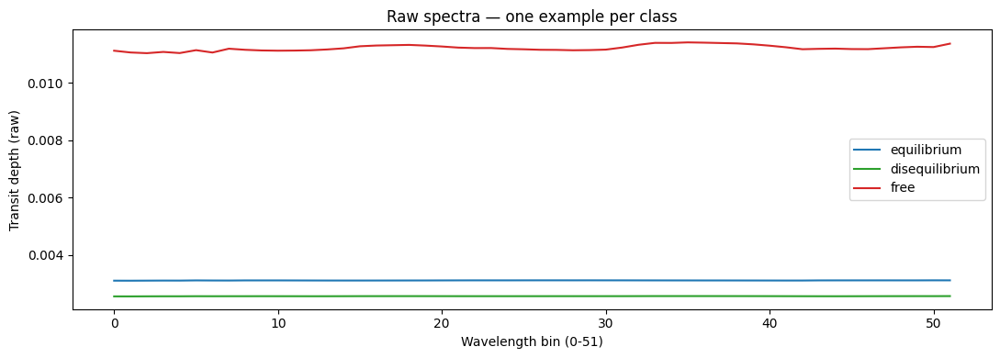

In [ ]:
import matplotlib.pyplot as plt

i_equi = np.where(labels == 0)[0][0]
i_diseq = np.where(labels == 1)[0][0]
i_free = np.where(labels == 2)[0][0]

plt.figure(figsize=(11, 4))
plt.plot(X[i_equi], label="equilibrium", color="tab:blue")
plt.plot(X[i_diseq], label="disequilibrium", color="tab:green")
plt.plot(X[i_free], label="free", color="tab:red")
plt.xlabel("Wavelength bin (0-51)")
plt.ylabel("Transit depth (raw)")
plt.title("Raw spectra — one example per class")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
X_zscore = (X - X.mean(axis = 1, keepdims=True))/(X.std(axis = 1, keepdims=True) + 1e-8)

print("Z-score norm X shape:", X_zscore.shape)
print("Row 0 mean (should be ~0):", X_zscore[0].mean())
print("Row 0 std (should be ~1):", X_zscore[0].std())

Z-score norm X shape: (25278, 52)
Row 0 mean (should be ~0): 9.352134451472256e-14
Row 0 std (should be ~1): 0.9967958318744342


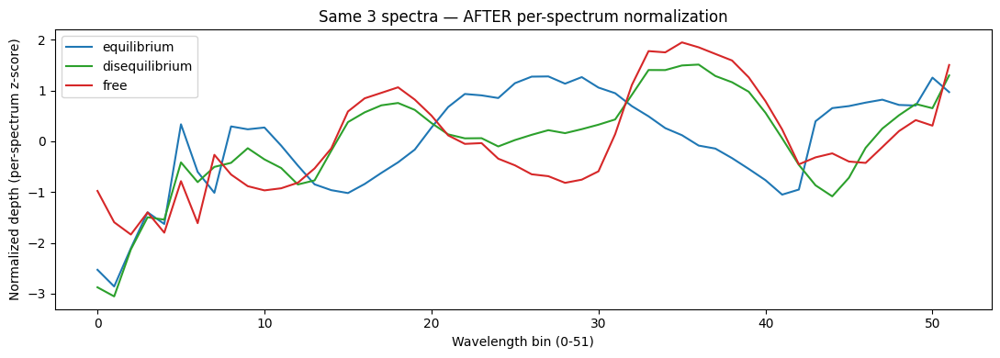

In [ ]:
plt.figure(figsize=(11, 4))
plt.plot(X_zscore[i_equi], label="equilibrium", color="tab:blue")
plt.plot(X_zscore[i_diseq], label="disequilibrium", color="tab:green")
plt.plot(X_zscore[i_free], label="free", color="tab:red")
plt.xlabel("Wavelength bin (0-51)")
plt.ylabel("Normalized depth (per-spectrum z-score)")
plt.title("Same 3 spectra — AFTER per-spectrum normalization")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_zscore)

print("X_scaled shape:", X_scaled.shape)
print("Column 0 mean (should be ~0):", X_scaled[:, 0].mean())
print("Column 0 std (should be ~1):", X_scaled[:, 0].std())

X_scaled shape: (25278, 52)
Column 0 mean (should be ~0): 1.0791097248924062e-15
Column 0 std (should be ~1): 1.0


# Variation A - with StandardScaler

In [ ]:
from sklearn.decomposition import PCA
import numpy as np

pca_A = PCA(n_components=6)
X_pca_A = pca_A.fit_transform(X_scaled)

print("X_pca_A shape:", X_pca_A.shape)

evr = pca_A.explained_variance_ratio_
print("Explained variance per component:", evr)
print()
print("Cumulative (running total):")
for k in range(6):
    print(f"  {k+1} components: {evr[:k+1].sum():.4f}")

X_pca_A shape: (25278, 6)
Explained variance per component: [0.44596339 0.17409244 0.10896829 0.08829712 0.06245776 0.0499089 ]

Cumulative (running total):
  1 components: 0.4460
  2 components: 0.6201
  3 components: 0.7290
  4 components: 0.8173
  5 components: 0.8798
  6 components: 0.9297


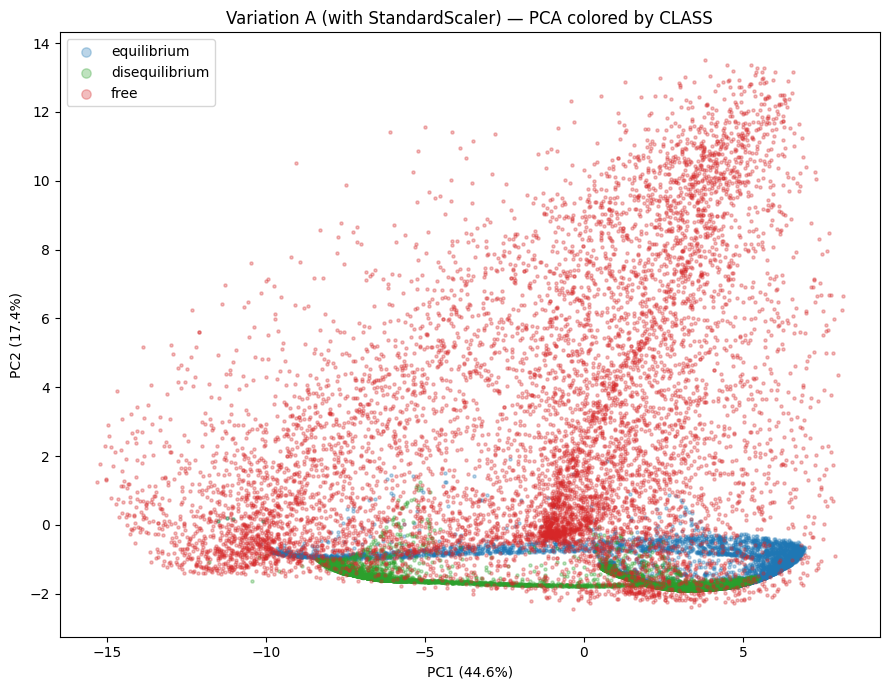

In [ ]:
import matplotlib.pyplot as plt

colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}

plt.figure(figsize=(9, 7))
for cls in [0, 1, 2]:
    mask = labels == cls
    plt.scatter(X_pca_A[mask, 0], X_pca_A[mask, 1],
                s=5, alpha=0.3, color=colors[cls], label=names[cls])

plt.xlabel("PC1 (44.6%)")
plt.ylabel("PC2 (17.4%)")
plt.title("Variation A (with StandardScaler) — PCA colored by CLASS")
plt.legend(markerscale=3)
plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px
import pandas as pd

# build a small dataframe for plotly
df = pd.DataFrame({
    "PC1": X_pca_A[:, 0],
    "PC2": X_pca_A[:, 1],
    "PC3": X_pca_A[:, 2],
    "class": [names[l] for l in labels]
})

fig = px.scatter_3d(df, x="PC1", y="PC2", z="PC3",
                    color="class",
                    color_discrete_map={"equilibrium": "blue",
                                        "disequilibrium": "green",
                                        "free": "red"},
                    opacity=0.4,
                    title="Variation A — interactive 3D PCA")
fig.update_traces(marker=dict(size=2))
fig.show()

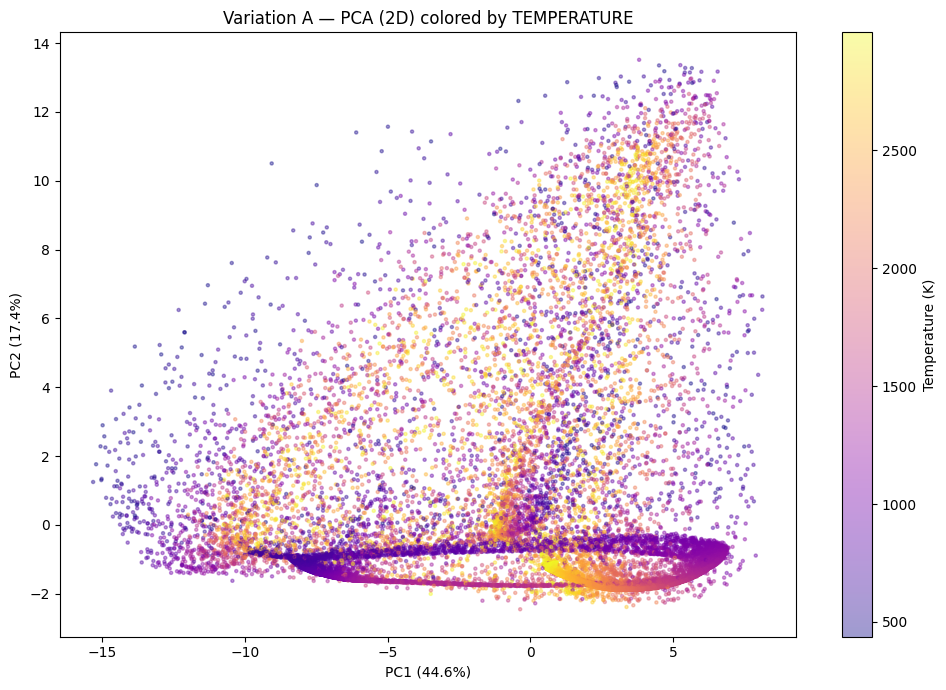

In [ ]:
plt.figure(figsize=(10, 7))
sc = plt.scatter(X_pca_A[:, 0], X_pca_A[:, 1],
                 c=T, cmap="plasma", s=5, alpha=0.4)
plt.colorbar(sc, label="Temperature (K)")
plt.xlabel("PC1 (44.6%)")
plt.ylabel("PC2 (17.4%)")
plt.title("Variation A — PCA (2D) colored by TEMPERATURE")
plt.tight_layout()
plt.show()

In [ ]:
df["temperature"] = T

fig = px.scatter_3d(df, x="PC1", y="PC2", z="PC3",
                    color="temperature",
                    color_continuous_scale="plasma",
                    opacity=0.4,
                    title="Variation A — interactive 3D PCA colored by TEMPERATURE")
fig.update_traces(marker=dict(size=2))
fig.show()

In [ ]:
from sklearn.cluster import KMeans
x_for_clustering = X_pca_A

kmeans = KMeans(n_clusters=3, random_state=42,n_init = 10)
clusters = kmeans.fit_predict(x_for_clustering)

print("Cluster shape", clusters.shape)
print("Cluster sizes:", np.bincount(clusters))

Cluster shape (25278,)
Cluster sizes: [ 2815  6593 15870]


In [ ]:
from sklearn.metrics import adjusted_rand_score,confusion_matrix
ari = adjusted_rand_score(labels, clusters)
print("Adjusted Rand Index:", ari)

cm = confusion_matrix(labels, clusters)
print("\nConfusion matrix (rows = true class, cols = cluster):")
print("            cluster0  cluster1  cluster2")
for i, name in enumerate(["equilibrium ", "disequilib. ", "free        "]):
    print(name, cm[i])

Adjusted Rand Index: 0.1280401550948219

Confusion matrix (rows = true class, cols = cluster):
            cluster0  cluster1  cluster2
equilibrium  [   0  781 7645]
disequilib.  [   0 2993 5433]
free         [2815 2819 2792]


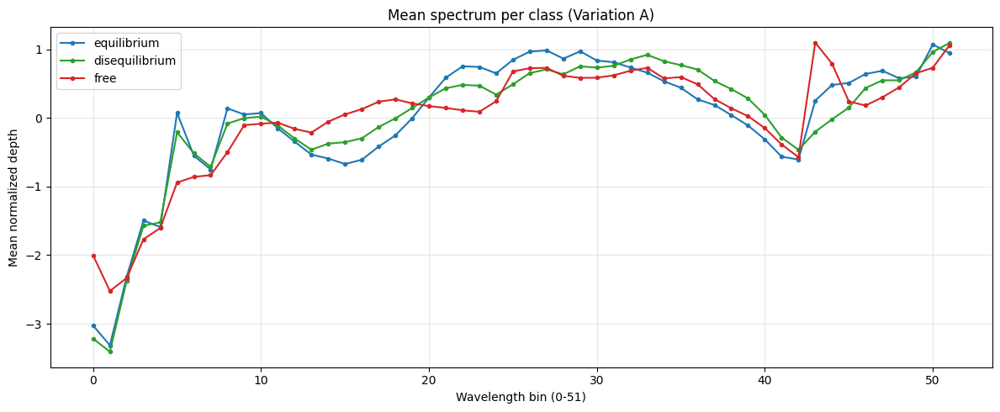

In [ ]:
import matplotlib.pyplot as plt

# average the per-spectrum-normalized spectra within each class
mean_equi = X_zscore[labels == 0].mean(axis=0)
mean_diseq = X_zscore[labels == 1].mean(axis=0)
mean_free = X_zscore[labels == 2].mean(axis=0)

plt.figure(figsize=(12, 5))
plt.plot(mean_equi, label="equilibrium", color="tab:blue", marker="o", markersize=3)
plt.plot(mean_diseq, label="disequilibrium", color="tab:green", marker="o", markersize=3)
plt.plot(mean_free, label="free", color="tab:red", marker="o", markersize=3)
plt.xlabel("Wavelength bin (0-51)")
plt.ylabel("Mean normalized depth")
plt.title("Mean spectrum per class (Variation A)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
wl_binned = np.load("wl_binned.npy")
print("wl_binned shape:", wl_binned.shape)
print("\nBin -> Wavelength (microns):")
for b in [5, 6, 7, 8, 13, 15, 17, 19, 42, 43, 44, 45, 46]:
    print(f"  bin {b:2d}: {wl_binned[b]:.3f} um")

wl_binned shape: (52,)

Bin -> Wavelength (microns):
  bin  5: 1.406 um
  bin  6: 1.550 um
  bin  7: 1.708 um
  bin  8: 1.884 um
  bin 13: 2.133 um
  bin 15: 2.219 um
  bin 17: 2.310 um
  bin 19: 2.403 um
  bin 42: 4.032 um
  bin 43: 4.305 um
  bin 44: 4.597 um
  bin 45: 4.909 um
  bin 46: 5.242 um


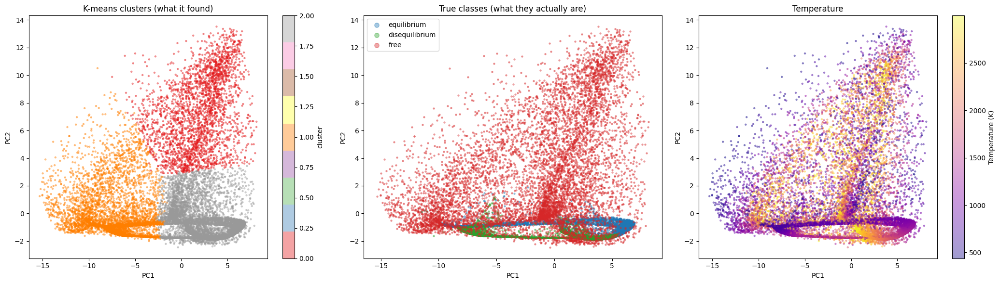

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# --- Panel 1: colored by K-MEANS CLUSTER ---
sc0 = axes[0].scatter(X_pca_A[:, 0], X_pca_A[:, 1],
                      c=clusters, cmap="Set1", s=5, alpha=0.4)
axes[0].set_title("K-means clusters (what it found)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(sc0, ax=axes[0], label="cluster")

# --- Panel 2: colored by TRUE CLASS ---
colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}
for cls in [0, 1, 2]:
    m = labels == cls
    axes[1].scatter(X_pca_A[m, 0], X_pca_A[m, 1],
                    s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes (what they actually are)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(markerscale=3)

# --- Panel 3: colored by TEMPERATURE ---
sc2 = axes[2].scatter(X_pca_A[:, 0], X_pca_A[:, 1],
                      c=T, cmap="plasma", s=5, alpha=0.4)
axes[2].set_title("Temperature")
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
plt.colorbar(sc2, ax=axes[2], label="Temperature (K)")

plt.tight_layout()
plt.savefig("variationA_cluster_comparison.png", dpi=150)
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score
sample_idx = np.random.default_rng(42).choice(len(clusters), 5000, replace=False)

sil = silhouette_score(X_pca_A[sample_idx, :6], clusters[sample_idx])
print("Silhouette score:", sil)

Silhouette score: 0.465512779072967


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

# subsample for speed (silhouette is slow)
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_pca_A), 5000, replace=False)
X_sample = X_pca_A[sample_idx, :6]

print("n_clusters | silhouette")
for k in [2, 3, 4, 5, 6, 7, 8]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbls = km.fit_predict(X_sample)
    sil = silhouette_score(X_sample, lbls)
    print(f"    {k}      |  {sil:.4f}")

n_clusters | silhouette
    2      |  0.4361
    3      |  0.4630
    4      |  0.4858
    5      |  0.4032
    6      |  0.4175
    7      |  0.3941
    8      |  0.4055


4-cluster sizes: [ 6356 14204  2027  2691]


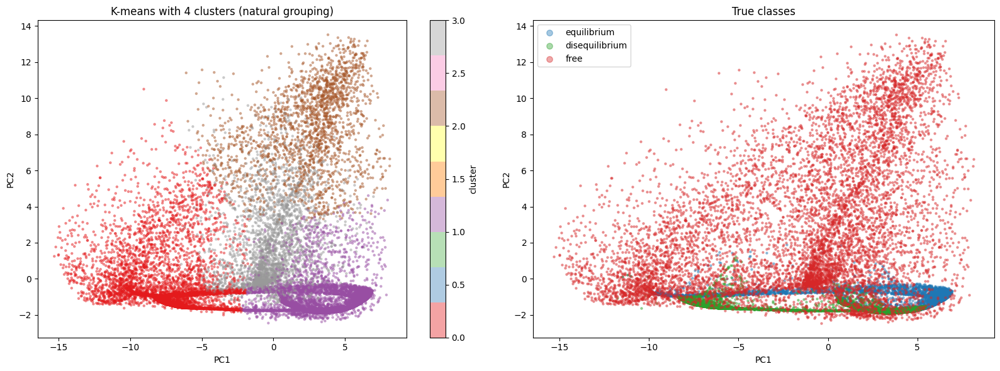

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# cluster the full data into 4
km4 = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters4 = km4.fit_predict(X_pca_A[:, :6])
print("4-cluster sizes:", np.bincount(clusters4))

# plot: 4-clusters next to true classes
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(X_pca_A[:, 0], X_pca_A[:, 1], c=clusters4, cmap="Set1", s=5, alpha=0.4)
axes[0].set_title("K-means with 4 clusters (natural grouping)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[0], label="cluster")

colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}
for cls in [0, 1, 2]:
    m = labels == cls
    axes[1].scatter(X_pca_A[m, 0], X_pca_A[m, 1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(markerscale=3)

plt.tight_layout()
plt.show()

In [ ]:
!pip install hdbscan -q

In [ ]:
import hdbscan
clusterer = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10)
hdb_labels = clusterer.fit_predict(X_pca_A[:, :6])
n_clusters_found = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)
n_noise = np.sum(hdb_labels == -1)

print("Clusters HDBSCAN found:", n_clusters_found)
print("Points labeled as noise:", n_noise)
print("Cluster sizes:", np.bincount(hdb_labels[hdb_labels >= 0]))

Clusters HDBSCAN found: 5
Points labeled as noise: 7961
Cluster sizes: [  723   816   665  3065 12048]


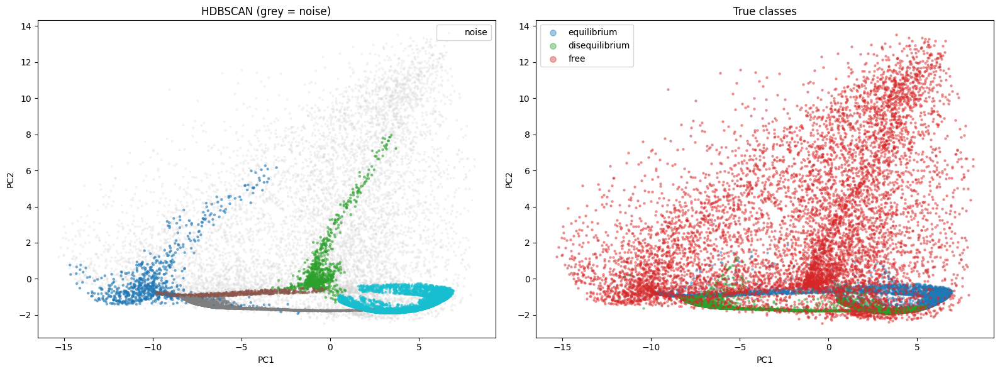

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# left: HDBSCAN clusters (noise = grey)
noise_mask = hdb_labels == -1
axes[0].scatter(X_pca_A[noise_mask, 0], X_pca_A[noise_mask, 1],
                s=4, alpha=0.2, color="lightgrey", label="noise")
sc = axes[0].scatter(X_pca_A[~noise_mask, 0], X_pca_A[~noise_mask, 1],
                     c=hdb_labels[~noise_mask], cmap="tab10", s=5, alpha=0.5)
axes[0].set_title("HDBSCAN (grey = noise)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].legend()

# right: true classes
colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}
for cls in [0, 1, 2]:
    m = labels == cls
    axes[1].scatter(X_pca_A[m, 0], X_pca_A[m, 1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(markerscale=3)

plt.tight_layout()
plt.show()

In [ ]:
!pip install umap-learn -q

In [ ]:
import umap

reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

print("UMAP output shape:", X_umap.shape)

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



UMAP output shape: (25278, 2)


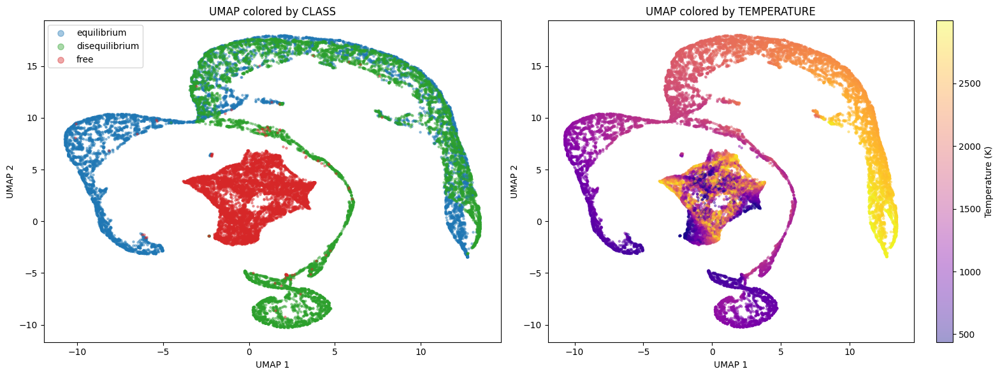

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# left: colored by true class
colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}
for cls in [0, 1, 2]:
    m = labels == cls
    axes[0].scatter(X_umap[m, 0], X_umap[m, 1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[0].set_title("UMAP colored by CLASS")
axes[0].set_xlabel("UMAP 1"); axes[0].set_ylabel("UMAP 2")
axes[0].legend(markerscale=3)

# right: colored by temperature
sc = axes[1].scatter(X_umap[:, 0], X_umap[:, 1], c=T, cmap="plasma", s=5, alpha=0.4)
axes[1].set_title("UMAP colored by TEMPERATURE")
axes[1].set_xlabel("UMAP 1"); axes[1].set_ylabel("UMAP 2")
plt.colorbar(sc, ax=axes[1], label="Temperature (K)")

plt.tight_layout()
plt.savefig("umap_class_temp.png", dpi=150)
plt.show()

In [ ]:
reducer_3d = umap.UMAP(n_components=3, n_neighbors=30, min_dist=0.1, random_state=42)
X_umap3 = reducer_3d.fit_transform(X_scaled)

print("X_umap3 shape:", X_umap3.shape)

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



X_umap3 shape: (25278, 3)


In [ ]:
import plotly.express as px
import pandas as pd

df3 = pd.DataFrame({
    "UMAP1": X_umap3[:, 0],
    "UMAP2": X_umap3[:, 1],
    "UMAP3": X_umap3[:, 2],
    "class": [ {0:"equilibrium",1:"disequilibrium",2:"free"}[l] for l in labels ]
})

fig = px.scatter_3d(df3, x="UMAP1", y="UMAP2", z="UMAP3",
                    color="class",
                    color_discrete_map={"equilibrium":"blue",
                                        "disequilibrium":"green",
                                        "free":"red"},
                    opacity=0.4,
                    title="3D UMAP colored by class")
fig.update_traces(marker=dict(size=2))
fig.show()

In [ ]:
df3["temperature"] = T

fig = px.scatter_3d(df3, x="UMAP1", y="UMAP2", z="UMAP3",
                    color="temperature",
                    color_continuous_scale="plasma",
                    opacity=0.4,
                    title="3D UMAP colored by temperature")
fig.update_traces(marker=dict(size=2))
fig.show()

In [ ]:
import hdbscan
import numpy as np

clusterer_umap = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10)
umap_hdb_labels = clusterer_umap.fit_predict(X_umap3)

n_clusters = len(set(umap_hdb_labels)) - (1 if -1 in umap_hdb_labels else 0)
n_noise = np.sum(umap_hdb_labels == -1)

print("Clusters found:", n_clusters)
print("Noise points:", n_noise)
print("Cluster sizes:", np.bincount(umap_hdb_labels[umap_hdb_labels >= 0]))

Clusters found: 4
Noise points: 424
Cluster sizes: [ 8350 13132  3117   255]


In [ ]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix

ari = adjusted_rand_score(labels, umap_hdb_labels)
print("ARI (UMAP-HDBSCAN vs true classes):", ari)

cm = confusion_matrix(labels, umap_hdb_labels) if -1 not in umap_hdb_labels else None
# handle noise: show crosstab including noise
import pandas as pd
print(pd.crosstab(pd.Series(labels, name="true"),
                  pd.Series(umap_hdb_labels, name="cluster")))

ARI (UMAP-HDBSCAN vs true classes): 0.586916234295184
cluster   -1     0     1     2    3
true                               
0        105     4  8317     0    0
1        300    11  4780  3092  243
2         19  8335    35    25   12


In [ ]:
import plotly.express as px
import pandas as pd

df_hdb = pd.DataFrame({
    "UMAP1": X_umap3[:, 0],
    "UMAP2": X_umap3[:, 1],
    "UMAP3": X_umap3[:, 2],
    "cluster": umap_hdb_labels.astype(str)   # as string so colors are discrete
})

fig = px.scatter_3d(df_hdb, x="UMAP1", y="UMAP2", z="UMAP3",
                    color="cluster",
                    opacity=0.4,
                    title="3D UMAP colored by HDBSCAN cluster")
fig.update_traces(marker=dict(size=2))
fig.show()

# Variation B - No scaling

In [ ]:
from sklearn.decomposition import PCA
import numpy as np

pca_B = PCA(n_components=7)
X_pca_B = pca_B.fit_transform(X_zscore)

print("Explained variance:", pca_B.explained_variance_ratio_)
print("Cumulative:")
for k in range(7):
    print(f"  {k+1}: {pca_B.explained_variance_ratio_[:k+1].sum():.4f}")

Explained variance: [0.47569168 0.23518559 0.08724492 0.07973733 0.03342502 0.02684019
 0.0202459 ]
Cumulative:
  1: 0.4757
  2: 0.7109
  3: 0.7981
  4: 0.8779
  5: 0.9113
  6: 0.9381
  7: 0.9584


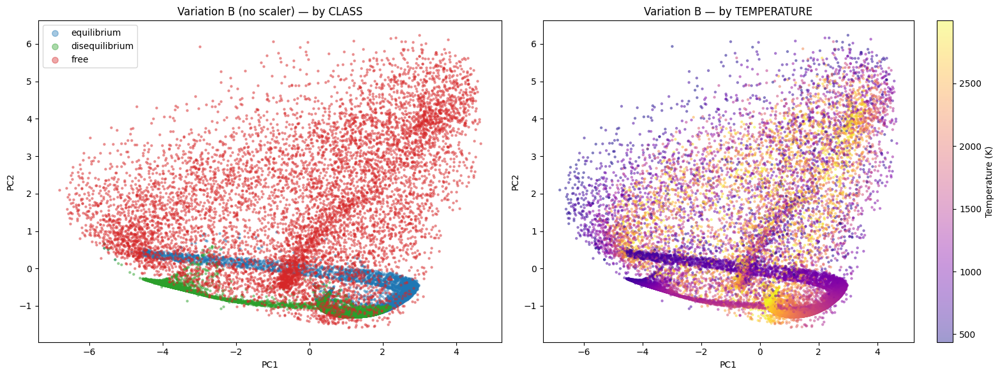

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = {0:"tab:blue",1:"tab:green",2:"tab:red"}
names = {0:"equilibrium",1:"disequilibrium",2:"free"}
for cls in [0,1,2]:
    m = labels == cls
    axes[0].scatter(X_pca_B[m,0], X_pca_B[m,1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[0].set_title("Variation B (no scaler) — by CLASS")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend(markerscale=3)

sc = axes[1].scatter(X_pca_B[:,0], X_pca_B[:,1], c=T, cmap="plasma", s=5, alpha=0.4)
axes[1].set_title("Variation B — by TEMPERATURE")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[1], label="Temperature (K)")
plt.tight_layout(); plt.savefig("varB_pca.png", dpi=150); plt.show()

In [ ]:
import plotly.express as px
import pandas as pd

names = {0:"equilibrium",1:"disequilibrium",2:"free"}

df_pca_B = pd.DataFrame({
    "PC1": X_pca_B[:,0], "PC2": X_pca_B[:,1], "PC3": X_pca_B[:,2],
    "class": [names[l] for l in labels],
    "temperature": T
})

fig = px.scatter_3d(df_pca_B, x="PC1", y="PC2", z="PC3", color="class",
                    color_discrete_map={"equilibrium":"blue","disequilibrium":"green","free":"red"},
                    opacity=0.4, title="Variation B — 3D PCA by CLASS")
fig.update_traces(marker=dict(size=2)); fig.show()

In [ ]:
fig = px.scatter_3d(df_pca_B, x="PC1", y="PC2", z="PC3", color="temperature",
                    color_continuous_scale="plasma",
                    opacity=0.4, title="Variation B — 3D PCA by TEMPERATURE")
fig.update_traces(marker=dict(size=2)); fig.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, confusion_matrix
import pandas as pd

kmB = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_B = kmB.fit_predict(X_pca_B[:, :7])
print("Cluster sizes:", np.bincount(clusters_B))
print("ARI:", adjusted_rand_score(labels, clusters_B))
print(pd.crosstab(pd.Series(labels,name="true"), pd.Series(clusters_B,name="cluster")))

Cluster sizes: [15442  6431  3405]
ARI: 0.1632253575377768
cluster     0     1     2
true                     
0        7704   722     0
1        5401  3025     0
2        2337  2684  3405


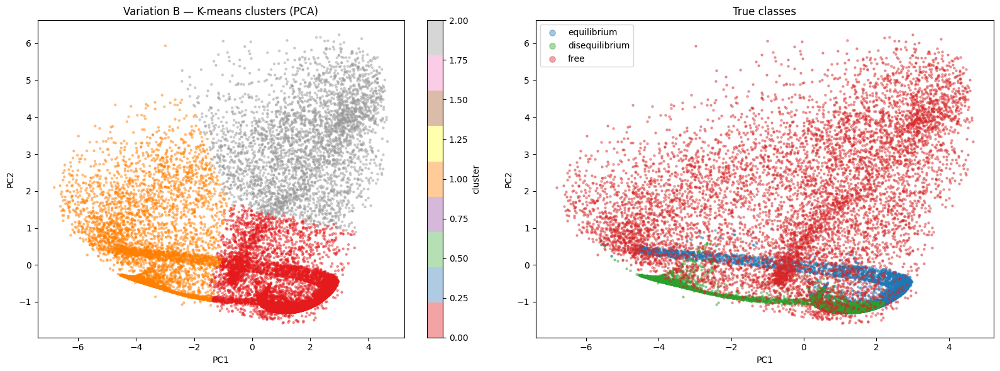

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(X_pca_B[:,0], X_pca_B[:,1], c=clusters_B, cmap="Set1", s=5, alpha=0.4)
axes[0].set_title("Variation B — K-means clusters (PCA)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[0], label="cluster")

colors = {0:"tab:blue",1:"tab:green",2:"tab:red"}
names = {0:"equilibrium",1:"disequilibrium",2:"free"}
for cls in [0,1,2]:
    m = labels == cls
    axes[1].scatter(X_pca_B[m,0], X_pca_B[m,1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].legend(markerscale=3)
plt.tight_layout(); plt.savefig("varB_kmeans.png", dpi=150); plt.show()

In [ ]:
from sklearn.metrics import silhouette_score
rng = np.random.default_rng(42)
sample = rng.choice(len(X_pca_B), 5000, replace=False)
print("k | silhouette (Variation B)")
for k in [2,3,4,5,6,7,8]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lb = km.fit_predict(X_pca_B[sample, :7])
    print(f"  {k}: {silhouette_score(X_pca_B[sample,:6], lb):.4f}")

k | silhouette (Variation B)
  2: 0.4566
  3: 0.4976
  4: 0.4957
  5: 0.4151
  6: 0.3990
  7: 0.4047
  8: 0.4121


In [ ]:
import hdbscan
clB = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10)
hdbB = clB.fit_predict(X_pca_B[:, :7])
nC = len(set(hdbB)) - (1 if -1 in hdbB else 0)
print("Clusters:", nC, "| Noise:", np.sum(hdbB==-1))
print("Sizes:", np.bincount(hdbB[hdbB>=0]))
print("ARI:", adjusted_rand_score(labels, hdbB))

Clusters: 5 | Noise: 7751
Sizes: [  999   592  3113   671 12152]
ARI: 0.4337350345411436


In [ ]:
import umap

reducer_2d_B = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
X_umap_2d_B = reducer_2d_B.fit_transform(X_zscore)
print("UMAP 2D shape:", X_umap_2d_B.shape)

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



UMAP 2D shape: (25278, 2)


In [ ]:
reducer_3d_B = umap.UMAP(n_components=3, n_neighbors=30, min_dist=0.1, random_state=42)
X_umap_3d_B = reducer_3d_B.fit_transform(X_zscore)
print("UMAP 3D shape:", X_umap_3d_B.shape)

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



UMAP 3D shape: (25278, 3)


In [ ]:
import hdbscan
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import numpy as np

# HDBSCAN on 2D UMAP
hdb_2d_B = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10).fit_predict(X_umap_2d_B)
# HDBSCAN on 3D UMAP
hdb_3d_B = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10).fit_predict(X_umap_3d_B)

print("=== 2D UMAP + HDBSCAN ===")
print("Clusters:", len(set(hdb_2d_B)) - (1 if -1 in hdb_2d_B else 0),
      "| Noise:", np.sum(hdb_2d_B == -1))
print("ARI:", adjusted_rand_score(labels, hdb_2d_B))
print()
print("=== 3D UMAP + HDBSCAN ===")
print("Clusters:", len(set(hdb_3d_B)) - (1 if -1 in hdb_3d_B else 0),
      "| Noise:", np.sum(hdb_3d_B == -1))
print("ARI:", adjusted_rand_score(labels, hdb_3d_B))

=== 2D UMAP + HDBSCAN ===
Clusters: 3 | Noise: 0
ARI: 0.557136554321089

=== 3D UMAP + HDBSCAN ===
Clusters: 5 | Noise: 101
ARI: 0.5916901470079611


In [ ]:
print("2D UMAP crosstab:")
print(pd.crosstab(pd.Series(labels, name="true"), pd.Series(hdb_2d_B, name="cluster")))
print("\n3D UMAP crosstab:")
print(pd.crosstab(pd.Series(labels, name="true"), pd.Series(hdb_3d_B, name="cluster")))

2D UMAP crosstab:
cluster    0     1     2
true                    
0        126     4  8296
1         76    12  8338
2          3  8352    71

3D UMAP crosstab:
cluster  -1     0     1     2    3    4
true                                   
0        42     4     0  8254  126    0
1        57    12  3280  4758   75  244
2         2  8358    25    23    3   15


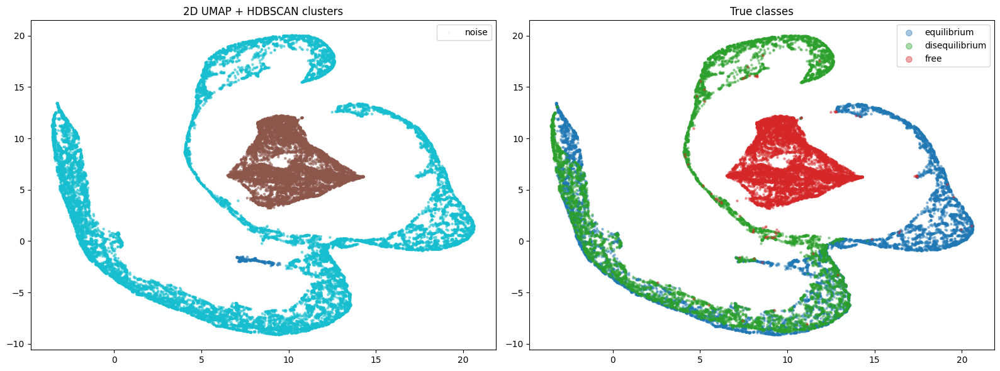

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
noise = hdb_2d_B == -1
axes[0].scatter(X_umap_2d_B[noise,0], X_umap_2d_B[noise,1], s=4, alpha=0.2, color="lightgrey", label="noise")
axes[0].scatter(X_umap_2d_B[~noise,0], X_umap_2d_B[~noise,1], c=hdb_2d_B[~noise], cmap="tab10", s=5, alpha=0.5)
axes[0].set_title("2D UMAP + HDBSCAN clusters"); axes[0].legend()

colors = {0:"tab:blue",1:"tab:green",2:"tab:red"}
names = {0:"equilibrium",1:"disequilibrium",2:"free"}
for cls in [0,1,2]:
    m = labels == cls
    axes[1].scatter(X_umap_2d_B[m,0], X_umap_2d_B[m,1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes"); axes[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

In [ ]:
import plotly.express as px
import pandas as pd

df_hdb3d = pd.DataFrame({
    "U1": X_umap_3d_B[:, 0],
    "U2": X_umap_3d_B[:, 1],
    "U3": X_umap_3d_B[:, 2],
    "cluster": hdb_3d_B.astype(str)
})

fig = px.scatter_3d(df_hdb3d, x="U1", y="U2", z="U3",
                    color="cluster",
                    opacity=0.4,
                    title="Variation B — 3D UMAP by HDBSCAN cluster")
fig.update_traces(marker=dict(size=2))
fig.show()